## Introduction

In this code, we access the ZARR datasets from ERA5/ECMWF. Please note that this is not an exact copy of the original ECMWF and that the time period is much less.

The aim is to show that in order to access this dataset, we need to do so through a "catalogue" using the SpatioTemporal Asset Catalog(STAC).

We see how to access the data here and how it is different than the CDS data.

In [27]:
!pip install adlfs planetary-computer rioxarray zarr --quiet

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import planetary_computer
import pystac_client
import xarray as xr
import zarr


In [3]:
# Initialize the STAC client
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1/"
)

In [4]:
collections = catalog.get_all_collections()

datasets = []
for col in collections:
    datasets.append({'collection': col.id, 'description': col.description})
df_col = pd.DataFrame(datasets)
df_col # If you uncomment this, you can easily browse the table in Google Colab

,collection,description
0,3dep-lidar-classification,This collection is derived from the [USGS 3DEP...
1,3dep-lidar-copc,This collection contains source data from the ...
2,3dep-lidar-dsm,This collection is derived from the [USGS 3DEP...
3,3dep-lidar-dtm,This collection is derived from the [USGS 3DEP...
4,3dep-lidar-dtm-native,This collection is derived from the [USGS 3DEP...
...,...,...
135,terraclimate,[TerraClimate](http://www.climatologylab.org/t...
136,us-census,The [2020 Census](https://www.census.gov/progr...
137,usda-cdl,The Cropland Data Layer (CDL) is a product of ...
138,usgs-lcmap-conus-v13,"The [Land Change Monitoring, Assessment, and P..."


In [5]:
df_dem = df_col[df_col["collection"].str.contains("dem", case=False, na=False)]
df_dem

,collection,description
10,alos-dem,"The ""ALOS World 3D-30m"" (AW3D30) dataset is a ..."
22,cop-dem-glo-30,The Copernicus DEM is a digital surface model ...
23,cop-dem-glo-90,The Copernicus DEM is a digital surface model ...
97,nasadem,[NASADEM](https://earthdata.nasa.gov/esds/comp...


In [6]:
df_era5 = df_col[df_col["collection"].str.contains("era5", case=False, na=False)]
df_era5

,collection,description
38,era5-pds,ERA5 is the fifth generation ECMWF atmospheric...


Let's see how we can access the data. This is in general the same for other datasets. Let's switch off the datetime_range and the bang_geometry.

In [11]:
# long min, lat min, long max, lat max
## india_geometry = [77, 12,  78, 14]
eur_geometry = [-25, 34, 45, 72]
datetime_range = "2020-01-01/2020-12-31"

## Code obtained from:
## https://colab.research.google.com/github/developmentseed/ingarss-workshop-2024/blob/main/book/docs/01_stac_and_zarr.ipynb#scrollTo=80311144
## And:
## https://www.technicalgis.com/code/era5-python-xarray/

search = catalog.search(
    collections=["era5-pds"],
    bbox=eur_geometry,
    datetime=datetime_range,
    query={
        "era5:kind": {
            "eq": "an"  # Filter for analysis data only - you also have "fc" for forecasts
        },
    }
)

In [12]:
items = search.item_collection()
print(f"Number of items: {len(items)}")

Number of items: 12


In [13]:
for item in items[0:5]: # delete the [0:5] in order to see the complete list
    # You will see that the last item is from December 1979
    print("Item ID:", item.id)
    print("Available assets:", list(item.assets.keys()))

Item ID: era5-pds-2020-12-an
Available assets: ['surface_air_pressure', 'sea_surface_temperature', 'eastward_wind_at_10_metres', 'air_temperature_at_2_metres', 'eastward_wind_at_100_metres', 'northward_wind_at_10_metres', 'northward_wind_at_100_metres', 'air_pressure_at_mean_sea_level', 'dew_point_temperature_at_2_metres']
Item ID: era5-pds-2020-11-an
Available assets: ['surface_air_pressure', 'sea_surface_temperature', 'eastward_wind_at_10_metres', 'air_temperature_at_2_metres', 'eastward_wind_at_100_metres', 'northward_wind_at_10_metres', 'northward_wind_at_100_metres', 'air_pressure_at_mean_sea_level', 'dew_point_temperature_at_2_metres']
Item ID: era5-pds-2020-10-an
Available assets: ['surface_air_pressure', 'sea_surface_temperature', 'eastward_wind_at_10_metres', 'air_temperature_at_2_metres', 'eastward_wind_at_100_metres', 'northward_wind_at_10_metres', 'northward_wind_at_100_metres', 'air_pressure_at_mean_sea_level', 'dew_point_temperature_at_2_metres']
Item ID: era5-pds-2020-09

In [14]:
dec_2020_item = items[0]
dec_2020_item

dec_2020_air_temp_asset = dec_2020_item.assets["air_temperature_at_2_metres"]

# Sign the asset URL for authentication
dec_2020_air_temp_asset = planetary_computer.sign(dec_2020_air_temp_asset)

# Display the asset
dec_2020_air_temp_asset

<Asset href=abfs://era5/ERA5/2020/12/air_temperature_at_2_metres.zarr>

In [15]:
%%time
# Open the dataset
dec_2020_ds = xr.open_dataset(
    dec_2020_air_temp_asset.href,
    **dec_2020_air_temp_asset.extra_fields["xarray:open_kwargs"]
)
dec_2020_ds.air_temperature_at_2_metres

CPU times: user 789 ms, sys: 80.8 ms, total: 870 ms
Wall time: 2.35 s


<xarray.DataArray 'air_temperature_at_2_metres' (time: 744, lat: 721, lon: 1440)> Size: 3GB
[772450560 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 6kB 2020-12-01 ... 2020-12-31T23:00:00
  * lat      (lat) float32 3kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float32 6kB 0.0 0.25 0.5 0.75 1.0 ... 359.0 359.2 359.5 359.8
Attributes:
    long_name:       2 metre temperature
    nameCDM:         2_metre_temperature_surface
    nameECMWF:       2 metre temperature
    product_type:    analysis
    shortNameECMWF:  2t
    standard_name:   air_temperature
    units:           K

In [17]:
%%time
dec_2020_ds = dec_2020_ds.compute()
dec_2020_ds.air_temperature_at_2_metres

CPU times: user 9.62 s, sys: 1.47 s, total: 11.1 s
Wall time: 23.8 s


<xarray.DataArray 'air_temperature_at_2_metres' (time: 744, lat: 721, lon: 1440)> Size: 3GB
array([[[260.25  , 260.25  , 260.25  , ..., 260.25  , 260.25  ,
         260.25  ],
        [260.3125, 260.3125, 260.3125, ..., 260.3125, 260.3125,
         260.3125],
        [260.1875, 260.1875, 260.1875, ..., 260.1875, 260.1875,
         260.1875],
        ...,
        [241.75  , 241.75  , 241.75  , ..., 241.75  , 241.75  ,
         241.75  ],
        [241.875 , 241.875 , 241.875 , ..., 241.8125, 241.8125,
         241.8125],
        [241.75  , 241.75  , 241.75  , ..., 241.75  , 241.75  ,
         241.75  ]],

       [[260.1875, 260.1875, 260.1875, ..., 260.1875, 260.1875,
         260.1875],
        [260.25  , 260.25  , 260.25  , ..., 260.1875, 260.1875,
         260.25  ],
        [260.1875, 260.1875, 260.1875, ..., 260.1875, 260.1875,
         260.1875],
...
        [242.625 , 242.625 , 242.625 , ..., 242.625 , 242.625 ,
         242.625 ],
        [242.5   , 242.5   , 242.5   , ..., 242.5   , 242.5   ,
         242.5   ],
        [242.25  , 242.25  , 242.25  , ..., 242.25  , 242.25  ,
         242.25  ]],

       [[263.8125, 263.8125, 263.8125, ..., 263.8125, 263.8125,
         263.8125],
        [264.0625, 264.0625, 264.0625, ..., 264.0625, 264.0625,
         264.0625],
        [264.3125, 264.3125, 264.3125, ..., 264.3125, 264.3125,
         264.3125],
        ...,
        [242.625 , 242.5625, 242.5625, ..., 242.625 , 242.625 ,
         242.625 ],
        [242.5   , 242.5   , 242.5   , ..., 242.5   , 242.5   ,
         242.5   ],
        [242.25  , 242.25  , 242.25  , ..., 242.25  , 242.25  ,
         242.25  ]]], shape=(744, 721, 1440), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 6kB 2020-12-01 ... 2020-12-31T23:00:00
  * lat      (lat) float32 3kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float32 6kB 0.0 0.25 0.5 0.75 1.0 ... 359.0 359.2 359.5 359.8
Attributes:
    long_name:       2 metre temperature
    nameCDM:         2_metre_temperature_surface
    nameECMWF:       2 metre temperature
    product_type:    analysis
    shortNameECMWF:  2t
    standard_name:   air_temperature
    units:           K

In [19]:
dec_2020_ds = dec_2020_ds.sel(
    lat=slice(72, 34),
    lon=slice(-25, 45)
)

dec_2020_ds.air_temperature_at_2_metres

<xarray.DataArray 'air_temperature_at_2_metres' (time: 744, lat: 153, lon: 181)> Size: 82MB
array([[[268.875 , 269.    , 269.1875, ..., 275.75  , 275.75  ,
         275.75  ],
        [269.375 , 269.5   , 269.6875, ..., 275.75  , 275.75  ,
         275.75  ],
        [269.9375, 270.    , 270.0625, ..., 275.8125, 275.75  ,
         275.8125],
        ...,
        [279.6875, 279.5   , 279.3125, ..., 281.75  , 282.0625,
         282.3125],
        [279.25  , 279.75  , 279.6875, ..., 281.8125, 282.125 ,
         282.375 ],
        [279.5625, 279.9375, 279.6875, ..., 281.8125, 282.25  ,
         282.375 ]],

       [[268.5   , 268.75  , 268.875 , ..., 275.75  , 275.75  ,
         275.75  ],
        [269.    , 269.1875, 269.375 , ..., 275.75  , 275.8125,
         275.8125],
        [269.625 , 269.75  , 269.875 , ..., 275.875 , 275.875 ,
         275.9375],
...
        [273.4375, 273.5625, 273.4375, ..., 281.25  , 281.5   ,
         281.6875],
        [273.9375, 273.9375, 274.125 , ..., 281.6875, 281.8125,
         281.75  ],
        [274.6875, 274.75  , 274.8125, ..., 282.5   , 282.5   ,
         282.25  ]],

       [[276.3125, 276.375 , 276.5625, ..., 270.    , 269.9375,
         269.875 ],
        [276.375 , 276.4375, 276.5625, ..., 269.6875, 269.5625,
         269.5   ],
        [276.375 , 276.4375, 276.5   , ..., 269.4375, 269.375 ,
         269.25  ],
        ...,
        [273.5   , 273.625 , 273.3125, ..., 281.125 , 281.6875,
         282.0625],
        [273.625 , 273.5   , 273.625 , ..., 281.5   , 281.8125,
         281.875 ],
        [274.0625, 274.0625, 274.125 , ..., 282.25  , 282.375 ,
         282.3125]]], shape=(744, 153, 181), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 6kB 2020-12-01 ... 2020-12-31T23:00:00
  * lat      (lat) float32 612B 72.0 71.75 71.5 71.25 ... 34.75 34.5 34.25 34.0
  * lon      (lon) float32 724B 0.0 0.25 0.5 0.75 1.0 ... 44.25 44.5 44.75 45.0
Attributes:
    long_name:       2 metre temperature
    nameCDM:         2_metre_temperature_surface
    nameECMWF:       2 metre temperature
    product_type:    analysis
    shortNameECMWF:  2t
    standard_name:   air_temperature
    units:           K

In [26]:
dec_2020_ds.air_temperature_at_2_metres.encoding['chunks']

(372, 150, 150)

In [20]:
dec_2020_ds.dims

FrozenMappingWarningOnValuesAccess({'time': 744, 'lat': 153, 'lon': 181})

Compute daily means:

In [21]:
december_daily_mean = dec_2020_ds.air_temperature_at_2_metres.resample(time='1D').mean()

In [22]:
december_daily_mean_celsius = december_daily_mean - 273.15

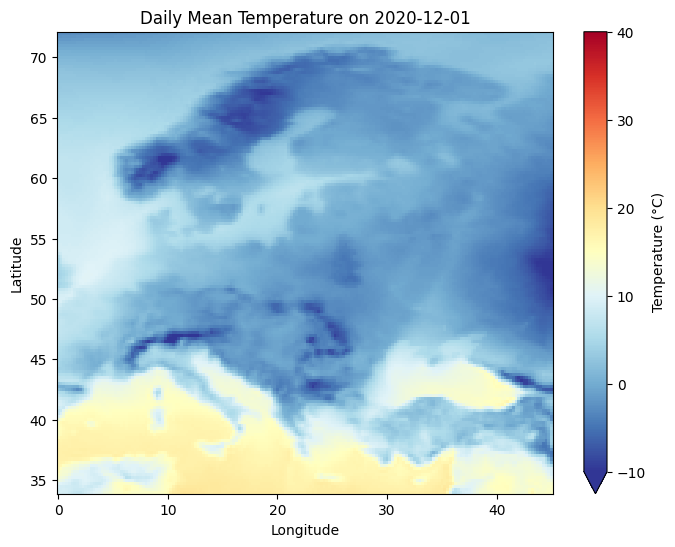

In [25]:
plt.figure(figsize=(8, 6))
december_daily_mean_celsius.sel(
    time='2020-12-01', method='nearest'
).plot(
    cmap='RdYlBu_r',
    cbar_kwargs={'label': 'Temperature (°C)'},
    vmin=-10,
    vmax=40
)
plt.title('Daily Mean Temperature on 2020-12-01')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

## References

https://colab.research.google.com/github/developmentseed/ingarss-workshop-2024/blob/main/book/docs/01_stac_and_zarr.ipynb#scrollTo=80311144

https://www.technicalgis.com/code/era5-python-xarray/